In [1]:
# hafta 11: GPT-2'yi hizli egitilebilir hale getirmek

#### gecen hafta GPT-2'yi yazip openai'nin agirliklariyla konusturdum. bu hafta ayni modeli hizli egitilebilir hale getiriyorum.
# plan:
#   task 1: metni batch'lere bolen bir data loader yaziyorum ve metnin tamaminda egitiyorum. weight tying'in kac parametre kazandirdigina
#           ve baslangic degerlerinde residual katmanlari neden kuculttugumuze bakiyorum.
#   task 2: bir egitim adiminin suresini olcuyorum, sonra videodaki hizlandirmalari tek tek ustune ekleyip her birinin ne kazandirdigini tabloya yaziyorum.
#   task 3: GPT-3 makalesinin egitim ayarlarini kuruyorum: AdamW, gradient clipping, warmup'li cosine learning rate, weight decay
#           ve kucuk gpu'da buyuk batch'le egitmek icin gradient accumulation.
# her sey colab'in ucretsiz T4 gpu'sunda calisti. ciktilardaki butun sureler T4'e ait.

In [2]:
%pip install -q tiktoken

In [3]:
import math, os, time, gc, urllib.request
from contextlib import nullcontext
from dataclasses import dataclass
import torch
import torch.nn as nn
from torch.nn import functional as F
import matplotlib.pyplot as plt
import tiktoken

if torch.cuda.is_available():
    device = 'cuda'
elif torch.backends.mps.is_available():
    device = 'mps'
else:
    device = 'cpu'

print('device :', device)
print('torch  :', torch.__version__)
if device == 'cuda':
    cap = torch.cuda.get_device_capability()
    print('gpu    :', torch.cuda.get_device_name(0), f'(compute capability {cap[0]}.{cap[1]})')
    print('bellek :', f'{torch.cuda.get_device_properties(0).total_memory / 1e9:.1f} GB')
    tf32_var = cap >= (8, 0)         # TF32 ve bfloat16 icin Ampere (A100, 8.0) ve sonrasi lazim
    bf16_var = cap >= (8, 0)
else:
    tf32_var = bf16_var = False
print('TF32 donanimda var mi    :', tf32_var)
print('bfloat16 donanimda var mi:', bf16_var)

def senkron():
    # gpu isleri sirayla kuyruga atiliyor, python beklemeden devam ediyor. sure olcmeden once kuyrugun bitmesini bekliyorum
    if device == 'cuda':
        torch.cuda.synchronize()
    elif device == 'mps':
        torch.mps.synchronize()

device : cuda
torch  : 2.11.0+cu130
gpu    : Tesla T4 (compute capability 7.5)
bellek : 15.6 GB
TF32 donanimda var mi    : False
bfloat16 donanimda var mi: False


## task 1
Data loader, weight tying ve başlangıç değerleri. Metni batch'lere bölen küçük bir data loader yaz ve metnin tamamında eğit. Weight tying'i ekle, kaç parametre kazandırdığını hesapla. Başlangıç değerlerini videodaki gibi ayarla: std 0.02, residual katmanlarda 1/√(2·n_layer) ile ölçekleme. Neden ölçeklediğimizi kendi cümlelerinle yaz. Geçen hafta ek görevde yaptıysan kısaca göstermen yeterli. (1:02:00 - 1:22:18)

In [4]:
@dataclass
class GPTConfig:
    block_size: int = 1024
    vocab_size: int = 50257
    n_layer: int = 12
    n_head: int = 12
    n_embd: int = 768
    flash: bool = False          # task 2: True ise attention F.scaled_dot_product_attention ile
    tying: bool = True           # weight tying acik mi
    scale_init: bool = True      # residual katmanlari 1/sqrt(2*n_layer) ile kucult

class CausalSelfAttention(nn.Module):
    def __init__(self, config):
        super().__init__()
        assert config.n_embd % config.n_head == 0
        self.n_head, self.n_embd, self.flash = config.n_head, config.n_embd, config.flash
        self.c_attn = nn.Linear(config.n_embd, 3 * config.n_embd)
        self.c_proj = nn.Linear(config.n_embd, config.n_embd)
        self.c_proj.SCALE_INIT = 1                                  # residual'a ekleme yapan katman
        tril = torch.tril(torch.ones(config.block_size, config.block_size))
        self.register_buffer('tril', tril.view(1, 1, config.block_size, config.block_size), persistent=False)

    def forward(self, x):
        B, T, C = x.shape
        hs = C // self.n_head
        q, k, v = self.c_attn(x).split(self.n_embd, dim=2)
        q = q.view(B, T, self.n_head, hs).transpose(1, 2)               # (B, nh, T, hs)
        k = k.view(B, T, self.n_head, hs).transpose(1, 2)
        v = v.view(B, T, self.n_head, hs).transpose(1, 2)
        if self.flash:
            y = F.scaled_dot_product_attention(q, k, v, is_causal=True)  # (T, T) matrisini bellege hic yazmadan
        else:
            wei = q @ k.transpose(-2, -1) * hs ** -0.5                  # (B, nh, T, T)
            wei = wei.masked_fill(self.tril[:, :, :T, :T] == 0, float('-inf'))
            wei = F.softmax(wei, dim=-1)
            y = wei @ v
        y = y.transpose(1, 2).contiguous().view(B, T, C)
        return self.c_proj(y)

class MLP(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.c_fc = nn.Linear(config.n_embd, 4 * config.n_embd)
        self.gelu = nn.GELU(approximate='tanh')
        self.c_proj = nn.Linear(4 * config.n_embd, config.n_embd)
        self.c_proj.SCALE_INIT = 1                                  # residual'a ekleme yapan katman

    def forward(self, x):
        return self.c_proj(self.gelu(self.c_fc(x)))

class Block(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.ln_1 = nn.LayerNorm(config.n_embd)
        self.attn = CausalSelfAttention(config)
        self.ln_2 = nn.LayerNorm(config.n_embd)
        self.mlp = MLP(config)

    def forward(self, x):
        x = x + self.attn(self.ln_1(x))
        x = x + self.mlp(self.ln_2(x))
        return x

class GPT(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.config = config
        self.transformer = nn.ModuleDict(dict(
            wte=nn.Embedding(config.vocab_size, config.n_embd),
            wpe=nn.Embedding(config.block_size, config.n_embd),
            h=nn.ModuleList([Block(config) for _ in range(config.n_layer)]),
            ln_f=nn.LayerNorm(config.n_embd),
        ))
        self.lm_head = nn.Linear(config.n_embd, config.vocab_size, bias=False)
        if config.tying:
            self.transformer.wte.weight = self.lm_head.weight      # giris tablosu ve cikis katmani ayni matris
        self.apply(self._init_weights)

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            std = 0.02
            if hasattr(module, 'SCALE_INIT') and self.config.scale_init:
                std *= (2 * self.config.n_layer) ** -0.5            # her blok residual'a 2 kez ekliyor: attn + mlp
            torch.nn.init.normal_(module.weight, mean=0.0, std=std)
            if module.bias is not None:
                torch.nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        pos = torch.arange(0, T, dtype=torch.long, device=idx.device)
        x = self.transformer.wte(idx) + self.transformer.wpe(pos)
        for block in self.transformer.h:
            x = block(x)
        x = self.transformer.ln_f(x)
        logits = self.lm_head(x)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))
        return logits, loss

In [5]:
#### model gecen haftaki GPT-2 sinifimla ayni, uc bayrak ekledim:
#   flash: attention'i elle mi (q @ k.T, maske, softmax) yoksa pytorch'un hazir F.scaled_dot_product_attention'i ile mi hesaplayayim. task 2'de lazim.
#   tying: weight tying acik mi. kazancini olcmek icin kapatabilmem lazim.
#   scale_init: residual katmanlari kucultuyor muyum. etkisini gostermek icin kapatabilmem lazim.
# baslangic degerleri videodaki gibi: butun linear ve embedding agirliklari ortalamasi 0, std'si 0,02 olan normal dagilimdan, bias'lar sifir.
# residual akisina ekleme yapan iki katman (attn.c_proj ve mlp.c_proj) bir de 1/sqrt(2 x n_layer) ile carpiliyor.
# 0,02 nereden geliyor: 1/sqrt(768) = 0,036, 1/sqrt(3072) = 0,018. yani xavier init'in verecegi araliga yakin, GPT-2'nin kodunda da bu sayi var.

In [6]:
# weight tying kac parametre kazandiriyor
p_tying = sum(p.numel() for p in GPT(GPTConfig(tying=True)).parameters())
p_ayri = sum(p.numel() for p in GPT(GPTConfig(tying=False)).parameters())
print(f'weight tying ile    : {p_tying:>12,d}')
print(f'weight tying olmadan: {p_ayri:>12,d}')
print(f'kazanc              : {p_ayri - p_tying:>12,d}  = 50257 x 768, 124M\'lik modelin %{100 * (p_ayri - p_tying) / p_tying:.1f}\'i kadar')

weight tying ile    :  124,439,808
weight tying olmadan:  163,037,184
kazanc              :   38,597,376  = 50257 x 768, 124M'lik modelin %31.0'i kadar


In [7]:
#### weight tying'i gecen hafta zaten eklemistim, burada sadece kazancini olcuyorum.
# tying varken 124.439.808 parametre, yokken 163.037.184. fark 38.597.376 = 50257 x 768, yani tam olarak bir token tablosu.
# 124 milyonluk modelin %31'i kadar bir parametreyi bedavaya kurtariyor.
# neden ise yariyor: giristeki tablo "bu token hangi vektor", cikistaki katman "bu vektor hangi token'a benziyor" sorusunu cevapliyor.
# anlamca yakin iki token (ornegin " cat" ve " dog") girista yakin vektorlere sahipse, cikista da ayni vektore benzer skor almalari dogal.
# ayni matrisi kullaninca bu iki is birbirini egitiyor: cikista gelen her gradient giris tablosunu da guncelliyor.
# nadir token'lar girista az gorulur ama cikista HER adimda (softmax'ta hepsi var) gradient alir, onlar da boylece daha iyi ogreniliyor.

In [8]:
# residual neden olceklenir: once oyuncak ornek. bir vektore ust uste 24 kez rastgele gurultu ekliyorum (12 blok x 2 ekleme)
torch.manual_seed(0)
n = 2 * 12
x = torch.zeros(768)
x_olcekli = torch.zeros(768)
for _ in range(n):
    x += torch.randn(768)
    x_olcekli += n ** -0.5 * torch.randn(768)
print(f'{n} ekleme sonra std, olceksiz: {x.std():.2f}   (beklenen sqrt({n}) = {n ** 0.5:.2f})')
print(f'{n} ekleme sonra std, olcekli : {x_olcekli.std():.2f}   (beklenen 1)')

24 ekleme sonra std, olceksiz: 5.01   (beklenen sqrt(24) = 4.90)
24 ekleme sonra std, olcekli : 1.01   (beklenen 1)


12 katman, olceksiz    giris std ~0.028  ->  son blok cikisi std 1.526


12 katman, olcekli     giris std ~0.028  ->  son blok cikisi std 0.293


48 katman, olceksiz    giris std ~0.028  ->  son blok cikisi std 3.124


48 katman, olcekli     giris std ~0.028  ->  son blok cikisi std 0.307


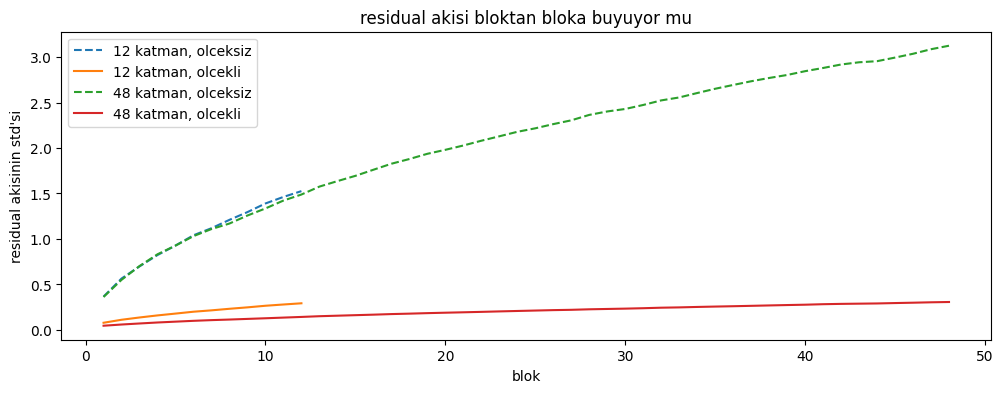

In [9]:
# simdi gercek modelde: rastgele baslatilmis GPT-2'de her bloktan cikan residual akisinin std'si
def blok_stdleri(scale_init, katman=12):
    torch.manual_seed(1337)
    m = GPT(GPTConfig(n_layer=katman, scale_init=scale_init)).to(device)
    stdler = []
    kancalar = [b.register_forward_hook(lambda mod, inp, out: stdler.append(out.std().item())) for b in m.transformer.h]
    with torch.no_grad():
        m(torch.randint(0, 50257, (4, 256), device=device))
    for k in kancalar:
        k.remove()
    return stdler

plt.figure(figsize=(12, 4))
for ad, katman in (('12 katman', 12), ('48 katman', 48)):
    for olcek, cizgi in ((False, '--'), (True, '-')):
        s = blok_stdleri(olcek, katman)
        etiket = f'{ad}, {"olcekli" if olcek else "olceksiz"}'
        plt.plot(range(1, katman + 1), s, cizgi, label=etiket)
        print(f'{etiket:22s} giris std ~0.028  ->  son blok cikisi std {s[-1]:.3f}')
plt.xlabel('blok')
plt.ylabel('residual akisinin std\'si')
plt.title('residual akisi bloktan bloka buyuyor mu')
plt.legend()
plt.show()

In [10]:
#### neden olcekliyoruz.
# her blok residual akisina iki kez bir sey ekliyor: x = x + attn(...), sonra x = x + mlp(...). 12 blokta toplam 24 ekleme.
# birbirinden bagimsiz rastgele seyleri ust uste toplayinca std toplanmiyor, varyans toplaniyor. 24 tane std'si 1 olan sey toplaninca std sqrt(24) = 4,9 oluyor.
# oyuncak ornekte tam bunu goruyorum: olceksiz 5,01. her eklemeyi 1/sqrt(24) ile carpinca 24 eklemenin toplami yine std 1: 1,01.
#
# gercek modelde de ayni sey oluyor. grafikte kesikli cizgiler olceksiz: residual akisinin std'si her blokta biraz daha buyuyor.
# 12 blokta 1,53'e, 48 blokta 3,12'ye cikiyor. 12 ve 48 katmanin ilk 12 blogu ust uste biniyor, cunku buyume katman sayisindan bagimsiz, her ekleme ayni.
# duz cizgiler olcekli: 12 katmanda son blok 0,29, 48 katmanda 0,31. model 4 kat derinlesti ama son std neredeyse ayni kaldi.
# yani olcekleme "toplam katki, katman sayisi ne olursa olsun ayni buyuklukte kalsin" diyor.
# neden onemli: residual akisi buyurse en sondaki layernorm onu yine toparlar, ama son bloklarin eklemeleri buyuk akisin yaninda kucuk kalir,
# katmanlar esit sekilde ise karismaz. derin modellerde bu dengesizlik egitimi zorlastiriyor. GPT-2 makalesi de bu olceklemeyi anlatiyor.

In [11]:
if not os.path.exists('input.txt'):
    urllib.request.urlretrieve('https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt', 'input.txt')

enc = tiktoken.get_encoding('gpt2')

class DataLoaderLite:
    def __init__(self, B, T):
        self.B, self.T = B, T
        with open('input.txt', 'r', encoding='utf-8') as f:
            text = f.read()
        self.tokens = torch.tensor(enc.encode(text))
        self.current_position = 0

    def next_batch(self):
        B, T = self.B, self.T
        buf = self.tokens[self.current_position: self.current_position + B * T + 1]
        x = buf[:-1].view(B, T)          # girdi
        y = buf[1:].view(B, T)           # hedef: bir adim kaydirilmis
        self.current_position += B * T
        if self.current_position + B * T + 1 > len(self.tokens):    # metnin sonuna geldiysek basa don
            self.current_position = 0
        return x.to(device), y.to(device)

B, T = 4, 1024
loader = DataLoaderLite(B, T)
print(f'metin: {len(loader.tokens):,d} token')
print(f'bir batch: {B} x {T} = {B * T:,d} token')
print(f'bir epoch (metnin tamami): {len(loader.tokens) // (B * T)} batch')

metin: 338,025 token
bir batch: 4 x 1024 = 4,096 token
bir epoch (metnin tamami): 82 batch


In [12]:
#### data loader cok basit: metnin tamamini token'lara ceviriyor ve bir isaretci tutuyor.
# her next_batch cagrisinda isaretcinin oldugu yerden B x T + 1 token kesiyor. ilk B x T girdi, bir kaydirilmis hali hedef.
# sonra isaretciyi B x T ilerletiyor. metnin sonuna gelince basa donuyor.
# gecen haftaki ezber testinden farki bu: orada hep ayni batch'i veriyordum, burada her adimda metnin bir sonraki parcasi geliyor.
# tiny shakespeare GPT-2 tokenizer'i ile 338.025 token. B=4, T=1024 ile bir batch 4.096 token, metnin tamami 82 batch'te bir kez goruluyor (1 epoch).

adim   0 | loss 10.9286 | 1283 ms | 3,192 token/sn


adim  10 | loss 7.3586 | 1136 ms | 3,605 token/sn


adim  20 | loss 6.8719 | 1161 ms | 3,527 token/sn


adim  30 | loss 6.4209 | 1181 ms | 3,469 token/sn


adim  40 | loss 6.2730 | 1213 ms | 3,378 token/sn


...

adim 110 | loss 5.9283 | 1237 ms | 3,311 token/sn


adim 120 | loss 5.6843 | 1236 ms | 3,314 token/sn


adim 130 | loss 5.6012 | 1252 ms | 3,271 token/sn


adim 140 | loss 5.6937 | 1252 ms | 3,272 token/sn


adim 149 | loss 5.6372 | 1252 ms | 3,272 token/sn


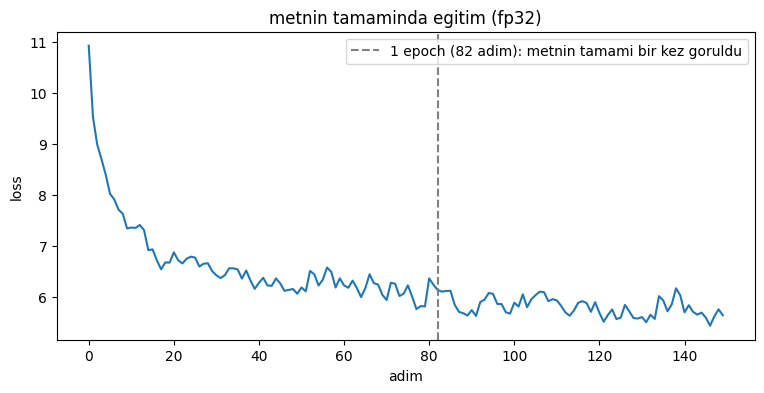

In [13]:
# metnin tamaminda egitim: hicbir hizlandirma yok, duz fp32
N_ADIM_T1 = 150
torch.manual_seed(1337)
model = GPT(GPTConfig()).to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4)
loader = DataLoaderLite(B, T)
kayip_t1 = []
for step in range(N_ADIM_T1):
    t0 = time.time()
    x, y = loader.next_batch()
    optimizer.zero_grad()
    logits, loss = model(x, y)
    loss.backward()
    optimizer.step()
    senkron()
    dt = time.time() - t0
    kayip_t1.append(loss.item())
    if step % 10 == 0 or step == N_ADIM_T1 - 1:
        print(f'adim {step:3d} | loss {loss.item():.4f} | {dt * 1000:.0f} ms | {B * T / dt:,.0f} token/sn')

epoch = len(loader.tokens) // (B * T)
plt.figure(figsize=(9, 4))
plt.plot(kayip_t1)
plt.axvline(epoch, color='gray', ls='--', label=f'1 epoch ({epoch} adim): metnin tamami bir kez goruldu')
plt.xlabel('adim')
plt.ylabel('loss')
plt.title('metnin tamaminda egitim (fp32)')
plt.legend()
plt.show()
del model, optimizer
gc.collect()
if device == 'cuda':
    torch.cuda.empty_cache()

In [14]:
#### metnin tamaminda 150 adim egittim, hicbir hizlandirma olmadan, duz fp32. yaklasik 1,8 epoch.
# loss 10,93'ten basliyor, gecen haftaki gibi ln(50257) = 10,82'ye yakin. ilk 20 adimda hizla 6,9'a iniyor, sonra yavasliyor, 150. adimda 5,64.
# ilk hizli dusus modelin en kolay seyi ogrenmesi: hangi token'lar sik geciyor (bosluk, virgul, "the", yeni satir). sonrasi gercek dil.
# egri gurultulu cunku her adim farkli bir batch: bazi parcalar digerlerinden daha zor.
# 82. adimdaki cizgiden sonra model ayni metni ikinci kez goruyor, loss bir miktar daha asagi iniyor. bunun bir kismi artik ezber.
# hiz: bir adim yaklasik 1,2-1,3 saniye, saniyede ~3.300 token. task 2'deki taban bu.

## task 2
Eğitimi hızlandır. Bir eğitim adımının süresini ve saniyede işlenen token sayısını ölç. Sonra videodaki adımları sırayla ekle: TF32, bfloat16 (ya da float16), torch.compile, flash attention, vocab'ı 50.304'e yuvarlamak. Her adımdan sonra süreyi tabloya yaz. Donanımın bir adımı desteklemiyorsa o adımı atla ve nedenini yaz, en az iki adımı ölçmen yeterli. Senin donanımında hangi adım en çok kazandırdı? (1:22:18 - 2:14:55)

In [15]:
amp_dtype = torch.bfloat16 if bf16_var else torch.float16
amp_ad = 'bfloat16' if bf16_var else 'float16'

def adim_suresi(ad, vocab_size=50257, flash=False, tf32=False, amp=False, derle=False, n_isinma=5, n_olcum=15):
    torch.set_float32_matmul_precision('high' if tf32 else 'highest')
    torch.manual_seed(1337)
    model = GPT(GPTConfig(vocab_size=vocab_size, flash=flash)).to(device)
    optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4)
    if derle:
        model = torch.compile(model)
    # float16'nin araligi dar, kucuk gradient'ler sifira yuvarlanabiliyor. GradScaler loss'u buyutup sonra gradient'leri geri kucultuyor.
    # bfloat16'da buna gerek yok, araligi float32 ile ayni.
    scaler = torch.amp.GradScaler(device, enabled=(amp and amp_dtype == torch.float16 and device == 'cuda'))
    ctx = torch.autocast(device_type=device, dtype=amp_dtype) if amp else nullcontext()
    loader = DataLoaderLite(B, T)
    if device == 'cuda':
        torch.cuda.reset_peak_memory_stats()
    sureler = []
    for i in range(n_isinma + n_olcum):
        x, y = loader.next_batch()
        senkron()
        t0 = time.time()
        optimizer.zero_grad()
        with ctx:
            logits, loss = model(x, y)
        scaler.scale(loss).backward()
        scaler.step(optimizer)
        scaler.update()
        senkron()
        if i >= n_isinma:                     # ilk adimlar isinma: torch.compile derlemesi ve gpu'nun ayaga kalkmasi burada
            sureler.append(time.time() - t0)
    sureler.sort()
    ms = 1000 * sureler[len(sureler) // 2]     # ortanca: arada bir yavas adim ortalamayi bozmasin
    bellek = torch.cuda.max_memory_allocated() / 1e9 if device == 'cuda' else float('nan')
    del model, optimizer
    gc.collect()
    if device == 'cuda':
        torch.cuda.empty_cache()
    torch._dynamo.reset()
    torch.set_float32_matmul_precision('highest')
    return dict(ad=ad, ms=ms, tok_s=B * T / (ms / 1000), bellek=bellek)

# her adim bir oncekinin ustune ekleniyor
adimlar = [
    ('fp32 (taban)',          dict()),
    ('+ TF32',                dict(tf32=True)),
    (f'+ {amp_ad} (autocast)', dict(tf32=True, amp=True)),
    ('+ torch.compile',       dict(tf32=True, amp=True, derle=True)),
    ('+ flash attention',     dict(tf32=True, amp=True, derle=True, flash=True)),
    ('+ vocab 50304',         dict(tf32=True, amp=True, derle=True, flash=True, vocab_size=50304)),
]

sonuclar = []
for ad, ayar in adimlar:
    t0 = time.time()
    try:
        r = adim_suresi(ad, **ayar)
        sonuclar.append(r)
        print(f'{ad:24s} {r["ms"]:7.1f} ms/adim  {r["tok_s"]:>8,.0f} token/sn  bellek {r["bellek"]:.1f} GB   (olcum {time.time() - t0:.0f} sn)')
    except Exception as e:
        sonuclar.append(dict(ad=ad, hata=f'{type(e).__name__}: {str(e)[:120]}'))
        print(f'{ad:24s} ATLANDI -> {type(e).__name__}: {str(e)[:120]}')

fp32 (taban)              1233.9 ms/adim     3,320 token/sn  bellek 11.6 GB   (olcum 30 sn)


+ TF32                    1236.6 ms/adim     3,312 token/sn  bellek 11.6 GB   (olcum 27 sn)


+ float16 (autocast)       487.6 ms/adim     8,400 token/sn  bellek 11.2 GB   (olcum 12 sn)


W1028 10:32:32.569000 1756 torch/_inductor/utils.py:1731] [0/0] Not enough SMs to use max_autotune_gemm mode


+ torch.compile            316.3 ms/adim    12,949 token/sn  bellek 9.1 GB   (olcum 48 sn)


+ flash attention          273.7 ms/adim    14,968 token/sn  bellek 6.7 GB   (olcum 32 sn)


+ vocab 50304              258.4 ms/adim    15,854 token/sn  bellek 6.4 GB   (olcum 30 sn)


B=4, T=1024 (4,096 token/adim), gpu: Tesla T4

adim                       ms/adim   token/sn  bu adimin kazanci  tabana gore   bellek
fp32 (taban)                1233.9      3,320                  -        1.00x    11.6G
+ TF32                      1236.6      3,312              1.00x        1.00x    11.6G
+ float16 (autocast)         487.6      8,400              2.54x        2.53x    11.2G
+ torch.compile              316.3     12,949              1.54x        3.90x     9.1G
+ flash attention            273.7     14,968              1.16x        4.51x     6.7G
+ vocab 50304                258.4     15,854              1.06x        4.78x     6.4G


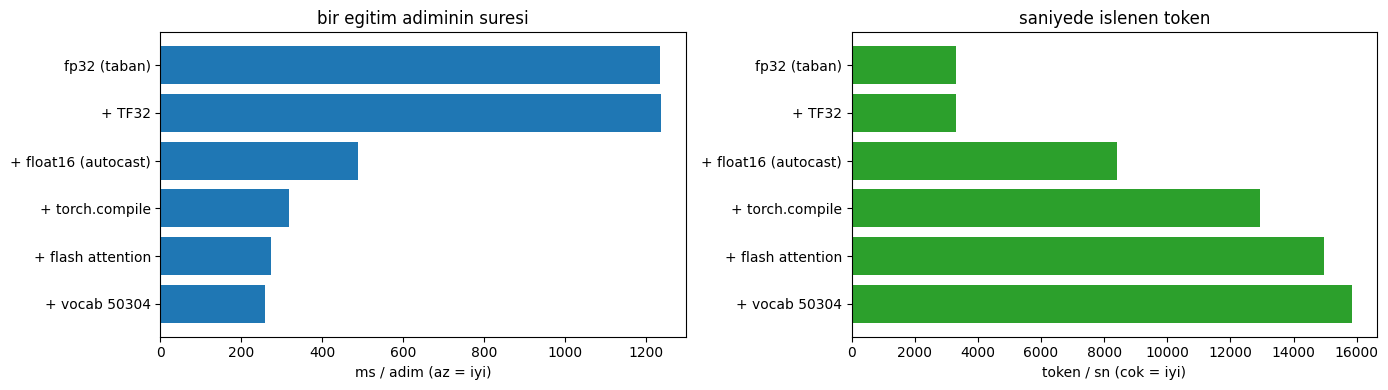

In [16]:
taban = sonuclar[0]['ms']
print(f'B={B}, T={T} ({B * T:,d} token/adim), gpu: {torch.cuda.get_device_name(0) if device == "cuda" else device}')
print()
print(f'{"adim":24s} {"ms/adim":>9s} {"token/sn":>10s} {"bu adimin kazanci":>18s} {"tabana gore":>12s} {"bellek":>8s}')
onceki = None
for r in sonuclar:
    if 'hata' in r:
        print(f'{r["ad"]:24s} atlandi: {r["hata"]}')
        continue
    kazanc = f'{onceki / r["ms"]:.2f}x' if onceki else '-'
    print(f'{r["ad"]:24s} {r["ms"]:9.1f} {r["tok_s"]:10,.0f} {kazanc:>18s} {taban / r["ms"]:11.2f}x {r["bellek"]:7.1f}G')
    onceki = r['ms']

olculen = [r for r in sonuclar if 'hata' not in r]
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].barh([r['ad'] for r in olculen][::-1], [r['ms'] for r in olculen][::-1], color='tab:blue')
ax[0].set_xlabel('ms / adim (az = iyi)')
ax[0].set_title('bir egitim adiminin suresi')
ax[1].barh([r['ad'] for r in olculen][::-1], [r['tok_s'] for r in olculen][::-1], color='tab:green')
ax[1].set_xlabel('token / sn (cok = iyi)')
ax[1].set_title('saniyede islenen token')
plt.tight_layout()
plt.show()

In [17]:
#### tabloyu okuyorum. her satir bir oncekinin ustune bir sey ekliyor. "bu adimin kazanci" bir onceki satira gore, "tabana gore" en basa gore.
# taban fp32: adim basina 1234 ms, saniyede 3.320 token.
# sonuna geldigimde: 258 ms, saniyede 15.854 token. ayni model, ayni batch, 4,8 kat hizli. bellek de 11,6 GB'tan 6,4 GB'a indi.
#
# benim donanimimda en cok kazandiran adim float16: tek basina 2,54 kat.
# ikinci torch.compile: 1,54 kat. sonra flash attention 1,16 kat, vocab 50304 1,06 kat.
# TF32 hicbir sey kazandirmadi: 1234 -> 1237 ms, olcum gurultusu. nedenini bir alttaki hucrede yaziyorum.
#
# kabaca bir hesap: bir egitim adimi yaklasik 6 x parametre x token kadar islem: 6 x 124M x 4096 ~ 3 trilyon islem.
# fp32 tabanda bu ~2,5 trilyon islem/sn demek. T4'un kagit uzerindeki fp32 tavani 8,1, yani gpu'nun dortte birini bile kullanmiyorum.
# sonda ~12 trilyon/sn. T4'un float16 tavani 65 trilyon, hala yolun cok basindayim, ama kucuk bir gpu'da 4,8 kat bedava hiz buyuk sey.

In [18]:
#### her adim ne yapiyor, ve benim T4'umde neden bu kadar kazandirdi:
#
# TF32 (ATLANDI, donanim desteklemiyor): A100 gibi Ampere ve sonrasi gpu'larda matris carpimini float32 yerine kirpilmis bir formatta (19 bit) yapan ozel cekirdekler var.
#    T4 bir onceki nesil (Turing, compute capability 7.5), bu cekirdekler yok. kodda yine actim ama tabloda gordugum gibi hicbir sey degismedi.
#    atladim demek yerine olctum, cunku "desteklemiyor"u sayiyla gormek daha ikna edici.
#
# float16 (autocast): T4'te bfloat16 da yok (o da Ampere ile geldi), ama float16 var ve T4'un tensor cekirdekleri tam bunun icin.
#    autocast matris carpimlarini float16'da, loss ve softmax gibi hassas yerleri float32'de yapiyor. sayilar yarim boyutta: hem islem hizli, hem bellekten tasima yarisi.
#    float16'nin bir sorunu var: araligi dar, cok kucuk gradient'ler sifira yuvarlanabiliyor. bu yuzden GradScaler kullaniyorum:
#    loss'u buyuk bir sayiyla carpip geri yayiyor, optimizer'a vermeden once gradient'leri geri boluyor. bfloat16'nin araligi float32 kadar genis, onda buna gerek yok.
#    T4'te en buyuk kazanc bu, cunku fp32 ile float16 arasindaki donanim farki T4'te devasa (8,1'e karsi 65 trilyon islem/sn).
#
# torch.compile: normalde pytorch her islemi (topla, carp, gelu, layernorm...) ayri ayri gpu'ya gonderiyor, her biri sonucu bellege yazip bir sonraki geri okuyor.
#    compile tum modeli onceden gorup kucuk islemleri tek cekirdekte birlestiriyor (kernel fusion): veri gpu'nun icinde kaliyor, bellege gidip gelmiyor.
#    1,54 kat hiz ve bellek 11,2 -> 9,1 GB. bedeli ilk adimdaki derleme suresi (tablodaki olcum suresi 48 sn, digerleri ~30).
#
# flash attention: elle yazdigim attention (B, 12, T, T) boyutunda bir matris uretiyor, T=1024'te her katmanda 4 x 12 x 1024 x 1024 sayi, bellege yazilip okunuyor.
#    F.scaled_dot_product_attention ayni sonucu bu matrisi hic bellege yazmadan, parca parca hesapliyor. islem sayisi ayni hatta biraz fazla, ama bellek trafigi cok az.
#    1,16 kat hiz, bellek 9,1 -> 6,7 GB: kazancin buyugu bellekte.
#
# vocab 50304: 50257 tek sayi, 50304 = 128 x 393. gpu cekirdekleri 32, 64, 128'lik bloklarla calisiyor, boyut buna tam bolunmezse kenarda verimsiz ekstra is yapiliyor.
#    47 tane hic gorulmeyecek sahte token ekledim. model onlarin olasiligini sifira itmeyi ogreniyor, zarari yok. sadece sayiyi "guzel" yapmak 1,06 kat kazandirdi.

## task 3
GPT-3'ün eğitim ayarlarını kur. AdamW'yi videodaki beta'larla kur, gradient clipping ekle ve her adımda gradient norm'u yazdır. Warmup'lı cosine learning rate schedule yaz ve eğrisini çiz. Weight decay'i yalnız 2 boyutlu parametrelere uygula, kaç parametreye uygulandığını yaz. Sonra gradient accumulation ekle: küçük batch'lerle büyük bir batch'in gradient'ini topla. Loss'u neden accumulation adım sayısına böldüğümüzü kendi cümlelerinle yaz. (2:14:55 - 2:46:52)

In [19]:
def configure_optimizers(model, weight_decay, learning_rate):
    params = {n: p for n, p in model.named_parameters() if p.requires_grad}
    decay = [p for n, p in params.items() if p.dim() >= 2]       # matrisler ve embedding tablolari
    nodecay = [p for n, p in params.items() if p.dim() < 2]      # bias'lar ve layernorm agirliklari
    groups = [
        {'params': decay, 'weight_decay': weight_decay},
        {'params': nodecay, 'weight_decay': 0.0},
    ]
    print(f'weight decay uygulanan  : {len(decay):3d} tensor, {sum(p.numel() for p in decay):>12,d} parametre')
    print(f'weight decay uygulanmayan: {len(nodecay):3d} tensor, {sum(p.numel() for p in nodecay):>12,d} parametre')
    fused = device == 'cuda'
    print('fused AdamW:', fused)
    return torch.optim.AdamW(groups, lr=learning_rate, betas=(0.9, 0.95), eps=1e-8, fused=fused)

_ = configure_optimizers(GPT(GPTConfig(vocab_size=50304)), weight_decay=0.1, learning_rate=6e-4)

weight decay uygulanan  :  50 tensor,  124,354,560 parametre
weight decay uygulanmayan:  98 tensor,      121,344 parametre
fused AdamW: True


In [20]:
#### weight decay her adimda agirliklari biraz sifira dogru cekiyor, boylece tek bir agirlik cok buyuyup her seyi tek basina tasiyamiyor.
# sadece 2 boyutlu parametrelere uyguluyorum: matris carpimi yapan agirliklar ve embedding tablolari. 50 tensor, 124.354.560 parametre.
# uygulamadiklarim 1 boyutlu olanlar: bias'lar ve layernorm'un olcek/kayma parametreleri. 98 tensor, sadece 121.344 parametre.
# neden: bunlar kaydirma ve olcekleme yapiyor, sifira cekmek modeli kisitlamaz sadece bozar. ornegin layernorm'un olcegini sifira cekmek o katmanin cikisini kapatmak demek.
# (vocab 50304 oldugu icin sayilar 124M'den biraz farkli.)
# AdamW videodaki ve GPT-3 makalesindeki ayarlarla: beta1 = 0,9, beta2 = 0,95, eps = 1e-8, weight decay 0,1.
# beta2 varsayilan 0,999 yerine 0,95: gradient buyuklugunun ortalamasini daha kisa bir gecmisten aliyor, ani degisimlere daha hizli uyum sagliyor.
# fused=True: tum parametrelerin guncellemesini tek bir cuda cekirdeginde yapiyor, 148 tensor icin ayri ayri dongu yerine.

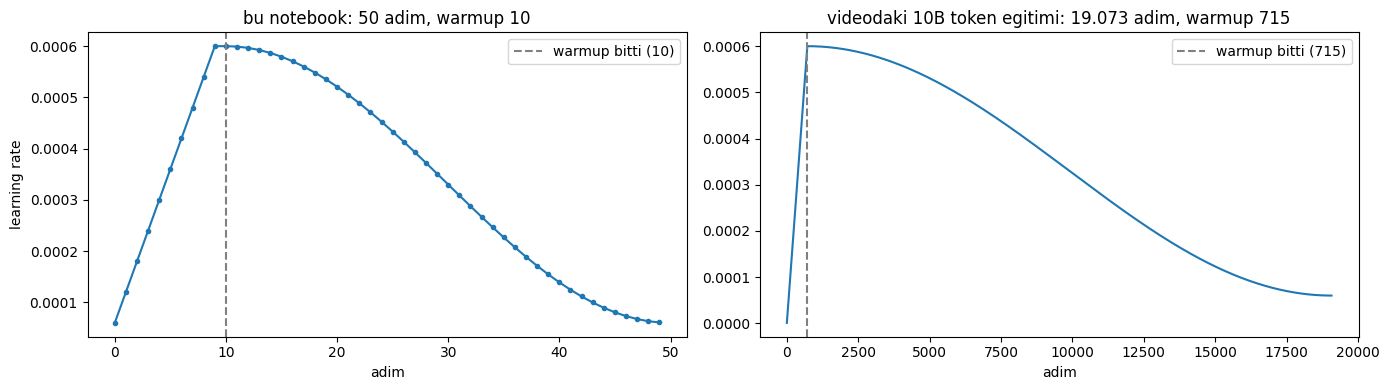

In [21]:
def get_lr(it, max_lr, min_lr, warmup_steps, max_steps):
    if it < warmup_steps:                                   # 1) warmup: 0'dan max_lr'a dogrusal
        return max_lr * (it + 1) / warmup_steps
    if it > max_steps:                                      # 3) bittikten sonra min_lr'da kal
        return min_lr
    oran = (it - warmup_steps) / (max_steps - warmup_steps)  # 2) arada: cosine ile max_lr'dan min_lr'a
    coeff = 0.5 * (1.0 + math.cos(math.pi * oran))          # 1'den 0'a yumusakca iner
    return min_lr + coeff * (max_lr - min_lr)

MAX_LR, MIN_LR = 6e-4, 6e-5
WARMUP, MAX_STEPS = 10, 50                                  # bu notebook'taki kisa egitim

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot([get_lr(i, MAX_LR, MIN_LR, WARMUP, MAX_STEPS) for i in range(MAX_STEPS)], marker='.')
ax[0].axvline(WARMUP, color='gray', ls='--', label=f'warmup bitti ({WARMUP})')
ax[0].set_title(f'bu notebook: {MAX_STEPS} adim, warmup {WARMUP}')
ax[0].set_xlabel('adim')
ax[0].set_ylabel('learning rate')
ax[0].legend()
# videodaki gercek egitim: 10 milyar token / 524.288 token'lik batch = 19.073 adim, warmup 375 milyon token = 715 adim
ax[1].plot([get_lr(i, MAX_LR, MIN_LR, 715, 19073) for i in range(19073)])
ax[1].axvline(715, color='gray', ls='--', label='warmup bitti (715)')
ax[1].set_title('videodaki 10B token egitimi: 19.073 adim, warmup 715')
ax[1].set_xlabel('adim')
ax[1].legend()
plt.tight_layout()
plt.show()

In [22]:
#### learning rate egrisi uc parcadan olusuyor:
#   1) warmup: ilk 10 adimda 0'dan 6e-4'e dogrusal cikiyor. basta model rastgele, gradient'ler buyuk ve tutarsiz. buyuk adim atarsa agirliklari bozabilir.
#      once kucuk adimlarla yerine oturuyor.
#   2) cosine: sonra kosinus seklinde yumusakca 6e-4'ten 6e-5'e iniyor. egitimin sonuna dogru dibe yaklastikca adimlari kucultuyor, etrafinda ziplamak yerine yerlesiyor.
#   3) bitis: max_steps'ten sonra 6e-5'te sabit (en kucuk deger en buyugun %10'u, GPT-3'teki gibi).
# soldaki benim bu notebook'taki kisa egitimim: 50 adim, 10 warmup.
# sagdaki videodaki gercek egitim: 10 milyar token, adim basina 524.288 token -> 19.073 adim. warmup GPT-3'teki gibi 375 milyon token = 715 adim.
# ayni fonksiyon, sadece sayilar farkli. 6e-4 GPT-3 makalesinin 125M'lik modeli (GPT-3 Small) icin verdigi deger.

In [23]:
# gradient accumulation neden loss'u boluyor: kucuk bir modelde sayiyla gosteriyorum
torch.manual_seed(0)
kucuk = GPT(GPTConfig(block_size=64, vocab_size=50304, n_layer=2, n_head=4, n_embd=128)).to(device)
tok = DataLoaderLite(8, 64).tokens[:8 * 64 + 1]
xb, yb = tok[:-1].view(8, 64).to(device), tok[1:].view(8, 64).to(device)

def gradlar():
    return torch.cat([p.grad.flatten() for p in kucuk.parameters()]).clone()

# 1) 8 satirlik batch tek seferde
kucuk.zero_grad()
_, loss = kucuk(xb, yb)
loss.backward()
g_tek = gradlar()

# 2) ayni batch 4 parcada (her biri 2 satir), loss'u 4'e bolerek biriktir
kucuk.zero_grad()
for i in range(4):
    _, l = kucuk(xb[2 * i:2 * i + 2], yb[2 * i:2 * i + 2])
    (l / 4).backward()            # backward gradient'i p.grad'in USTUNE ekliyor, sifirlamiyor
g_bolerek = gradlar()

# 3) ayni 4 parca, bolmeden
kucuk.zero_grad()
for i in range(4):
    _, l = kucuk(xb[2 * i:2 * i + 2], yb[2 * i:2 * i + 2])
    l.backward()
g_bolmeden = gradlar()

print(f'tek seferde vs 4 parca + bolerek : en buyuk fark {(g_tek - g_bolerek).abs().max().item():.2e}')
print(f'tek seferde vs 4 parca + bolmeden: en buyuk fark {(g_tek - g_bolmeden).abs().max().item():.2e}')
print(f'gradient boyu (norm): tek {g_tek.norm():.4f} | bolerek {g_bolerek.norm():.4f} | bolmeden {g_bolmeden.norm():.4f}  -> {g_bolmeden.norm() / g_tek.norm():.2f} kat')

tek seferde vs 4 parca + bolerek : en buyuk fark 1.49e-07
tek seferde vs 4 parca + bolmeden: en buyuk fark 9.35e-01
gradient boyu (norm): tek 3.0688 | bolerek 3.0688 | bolmeden 12.2752  -> 4.00 kat


In [24]:
#### gradient accumulation: GPT-3 small 0,5 milyon token'lik batch'le egitilmis. T4'e bir seferde 4.096 token sigiyor.
# cozum: kucuk batch'leri art arda gecirip gradient'lerini toplamak, optimizer'i ancak sonra bir kez calistirmak.
# pytorch'ta bu bedava: backward() gradient'i p.grad'in ustune ekliyor, sifirlamiyor. zero_grad() cagirmadigim surece birikiyor.
#
# neden loss'u birikim adim sayisina boluyorum:
# cross entropy batch'teki token'larin ORTALAMA loss'u. 8 satirlik batch'in loss'u, 8 satirin ortalamasi.
# 4 parcaya bolunce her parca kendi 2 satirinin ortalamasini veriyor. backward'lari toplarsam 4 ortalamanin TOPLAMINI almis oluyorum, ortalamasini degil.
# toplam, ortalamanin 4 kati. gradient de 4 kat buyuk cikar. 4'e bolunce ortalamaya geri donuyorum.
#
# kucuk bir modelde sayiyla gosterdim:
#   tek seferde vs 4 parca + bolerek: en buyuk fark 1,5e-7, yani float32'nin son basamaklari. ayni gradient.
#   tek seferde vs 4 parca + bolmeden: fark 0,93. gradient'in boyu 3,07'ye karsi 12,28, tam 4,00 kat.
# bolmeseydim learning rate'i farkinda olmadan birikim adim sayisiyla carpmis olurdum. 8 birikimde 8 kat, videodaki 128 birikimde 128 kat. egitim patlardi.

In [25]:
# hepsi bir arada: task 2'nin hizlandirmalari + GPT-3 ayarlari + gradient accumulation
total_batch_size = 32768                       # token. videoda 524.288 (GPT-3 small'un 0,5M'u), T4 icin 16'da biri
B, T = 4, 1024
grad_accum_steps = total_batch_size // (B * T)
print(f'istenen batch: {total_batch_size:,d} token | bir seferde {B} x {T} = {B * T:,d} | birikim adimi: {grad_accum_steps}')

torch.set_float32_matmul_precision('high')
torch.manual_seed(1337)
model = GPT(GPTConfig(vocab_size=50304, flash=True)).to(device)
optimizer = configure_optimizers(model, weight_decay=0.1, learning_rate=MAX_LR)
model_c = torch.compile(model) if device == 'cuda' else model
scaler = torch.amp.GradScaler(device, enabled=(amp_dtype == torch.float16 and device == 'cuda'))
ctx = torch.autocast(device_type=device, dtype=amp_dtype)
loader = DataLoaderLite(B, T)
kayit = dict(loss=[], norm=[], lr=[], ms=[])

for step in range(MAX_STEPS):
    t0 = time.time()
    optimizer.zero_grad()
    loss_accum = 0.0
    for micro in range(grad_accum_steps):
        x, y = loader.next_batch()
        with ctx:
            logits, loss = model_c(x, y)
        loss = loss / grad_accum_steps
        loss_accum += loss.detach()
        scaler.scale(loss).backward()
    scaler.unscale_(optimizer)                                         # clipping gercek gradient'e bakmali, buyutulmus olana degil
    norm = torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)     # norm 1'den buyukse 1'e kucult
    lr = get_lr(step, MAX_LR, MIN_LR, WARMUP, MAX_STEPS)
    for g in optimizer.param_groups:
        g['lr'] = lr
    scaler.step(optimizer)
    scaler.update()
    senkron()
    dt = time.time() - t0
    kayit['loss'].append(loss_accum.item()); kayit['norm'].append(norm.item()); kayit['lr'].append(lr); kayit['ms'].append(dt * 1000)
    print(f'adim {step:3d} | loss {loss_accum.item():.4f} | lr {lr:.2e} | norm {norm.item():7.3f} | {dt * 1000:6.0f} ms | {total_batch_size / dt:,.0f} token/sn')

istenen batch: 32,768 token | bir seferde 4 x 1024 = 4,096 | birikim adimi: 8


weight decay uygulanan  :  50 tensor,  124,354,560 parametre
weight decay uygulanmayan:  98 tensor,      121,344 parametre
fused AdamW: True


adim   0 | loss 10.9402 | lr 6.00e-05 | norm  29.883 |   3116 ms | 10,518 token/sn


adim   1 | loss 9.6733 | lr 1.20e-04 | norm   9.533 |   1861 ms | 17,607 token/sn


adim   2 | loss 9.2101 | lr 1.80e-04 | norm   4.863 |   1860 ms | 17,621 token/sn


...

adim  45 | loss 5.9071 | lr 8.06e-05 | norm   0.659 |   1732 ms | 18,920 token/sn


adim  46 | loss 5.9076 | lr 7.32e-05 | norm   0.618 |   1738 ms | 18,855 token/sn


adim  47 | loss 5.9224 | lr 6.75e-05 | norm   0.587 |   1740 ms | 18,836 token/sn


adim  48 | loss 6.0056 | lr 6.33e-05 | norm   0.683 |   1748 ms | 18,749 token/sn


adim  49 | loss 5.8970 | lr 6.08e-05 | norm   0.755 |   1737 ms | 18,862 token/sn


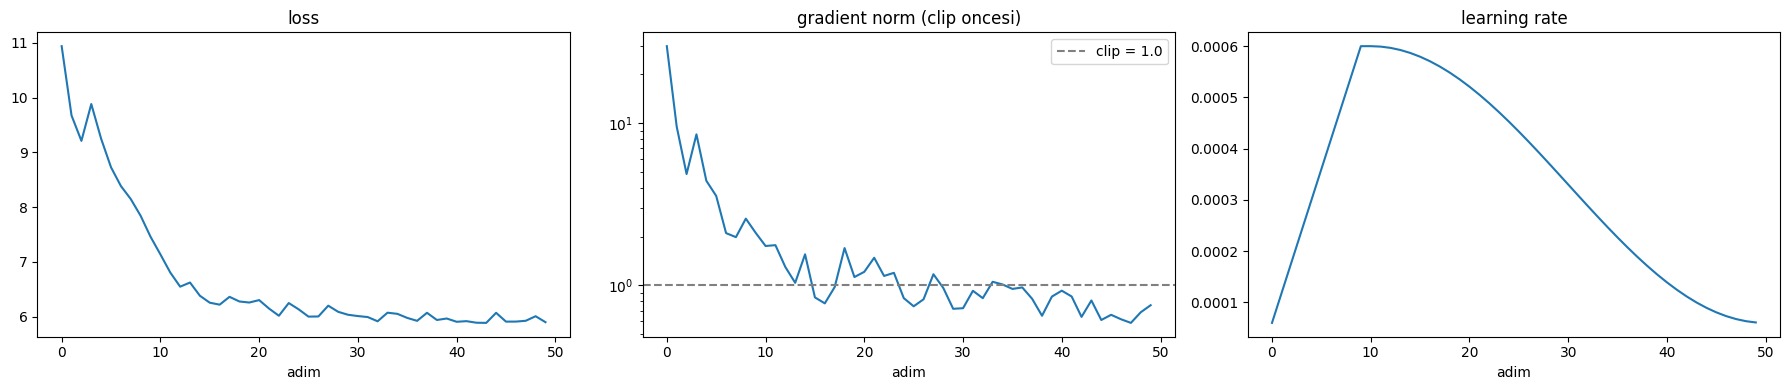

In [26]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4))
ax[0].plot(kayit['loss']); ax[0].set_title('loss'); ax[0].set_xlabel('adim')
ax[1].plot(kayit['norm']); ax[1].axhline(1.0, color='gray', ls='--', label='clip = 1.0'); ax[1].set_yscale('log')
ax[1].set_title('gradient norm (clip oncesi)'); ax[1].set_xlabel('adim'); ax[1].legend()
ax[2].plot(kayit['lr']); ax[2].set_title('learning rate'); ax[2].set_xlabel('adim')
plt.tight_layout()
plt.show()

In [27]:
#### hepsini bir arada calistirdim: float16 + compile + flash attention + vocab 50304, GPT-3 ayarlari ve gradient accumulation.
# istedigim batch 32.768 token, bir seferde 4.096 sigiyor, yani her optimizer adiminda 8 birikim adimi.
# (videodaki 524.288'i de kurabilirdim, birikim 128 olurdu, ama T4'te her adim ~27 saniye surerdi. mantik ayni, sadece sayi farkli.)
#
# loss: 10,94'ten basliyor, warmup bitince (10. adim) 7,1, 50. adimda 5,90.
# 3. adimdaki ziplama (9,21 -> 9,88) warmup sirasinda: lr hizla artarken model henuz oturmamis. sonra duzeliyor.
# task 1'deki egitim 150 adimda 5,64'e inmisti, burada 50 adimda 5,90. burada adim basina 8 kat token var ama sadece 50 guncelleme yapiliyor.
# egitimin basinda guncelleme sayisi token sayisindan daha onemli: buyuk batch gradient'i daha az gurultulu yapiyor ama bu asamada model zaten kaba yonu kolayca buluyor.
#
# gradient norm (clip oncesi, ortadaki grafik, log eksen): ilk adimda 29,9. clip olmasa bu adim agirliklari 30 kat buyuk bir adimla sarsardi.
# clip_grad_norm_ toplam norm 1'den buyukse butun gradient'leri ayni oranda kucultup norm'u 1 yapiyor: yon ayni kaliyor, sadece boy kisaltiliyor.
# ilk 15 adimda norm hep 1'in ustunde, yani clip her adimda devrede. sonra cogunlukla 0,6-1,0 arasina iniyor, clip arada bir devreye giriyor.
# norm'un yerlesip sakinlesmesi egitimin saglikli gittiginin isareti. birden ziplarsa bir sorun var demektir (videoda karpathy de boyle izliyor).
# float16 icin bir not: clip'ten once scaler.unscale_ cagiriyorum, yoksa GradScaler'in buyuttugu gradient'in norm'una bakardim.
#
# hiz: ilk adim 3,1 sn (isinma), sonra adim basina ~1,7 sn, saniyede ~19.000 token.
# task 2 tablosundaki 15.854'ten bile yuksek: buradaki optimizer fused AdamW ve 8 mikro-adimda bir kez calisiyor, tablodaki her 4.096 token'da bir.

In [28]:
#### ozet
# - data loader metni sirayla batch'lere boluyor. tiny shakespeare 338 bin token, 82 batch'te bir epoch. fp32'de 150 adimda loss 10,93 -> 5,64.
# - weight tying 38,6 milyon parametre kazandiriyor, modelin %31'i.
# - residual katmanlarini 1/sqrt(2 x n_layer) ile kucultmek, katman sayisi ne olursa olsun residual akisini ayni boyda tutuyor: 48 katmanda olceksiz std 3,12, olcekli 0,31.
# - T4'te hizlandirma: fp32 1234 ms -> 258 ms, 4,8 kat. en buyuk kazanc float16 (2,54 kat), sonra torch.compile (1,54 kat).
#   TF32 ve bfloat16 T4'te yok (Ampere ile geldi), TF32'yi olctum, hicbir sey degismedi.
# - GPT-3 ayarlari: AdamW (0,9 / 0,95, eps 1e-8), gradient clipping 1,0, warmup'li cosine lr (6e-4 -> 6e-5), weight decay 0,1 sadece 2 boyutlu 124,35M parametreye.
# - gradient accumulation'da loss'u bolmezsem gradient tam birikim sayisi kadar buyuyor (4 parcada 4,00 kat), bolunce tek seferdekiyle ayni.
# - hepsi bir arada: 32.768 token'lik batch, 50 adimda loss 10,94 -> 5,90, saniyede ~19.000 token.